# Step 1 - Classical baseline: TF-IDF vectorizers + classical models

1. **Vectorizer (TF-IDF).** For each text we count how often every word (or word pair, or group of characters) appears. Words that are common everywhere ("the", "and") get a low weight; words that are rare but frequent in this text get a high weight. That is TF-IDF (term frequency, inverse document frequency).
   - **Word n-grams (1-2):** single words and pairs of words ("let me", "in conclusion"). They capture *vocabulary and phrasing*.
   - **Character n-grams (2-5):** chunks of 2-5 letters inside words (including punctuation and spaces). They capture *style* (typical endings, punctuation habits, typos) and work well for both English and German.
2. **Classical model.** A linear model (Logistic Regression or a linear SVM) learns one weight per feature: "this word pushes towards ai", "that one towards human". Prediction = add up the weights.
3. **Small parameter search.** These models have a strength setting `C` (how strongly they are allowed to fit the training data). Too small = too simple, too large = memorises noise. We try a few values and keep the best one. **The search is done inside the training data** (an internal hold-out), so the validation set stays untouched.
4. **Evaluation on the validation set.** Per-class precision / recall / F1 and a confusion matrix show *where* the model is right and wrong. The headline metric is **macro-F1** (the plain average of the F1 of the three classes, so the hard class `fusion` counts as much as the easy ones).

In [1]:
import os, glob, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

_hits = glob.glob("/kaggle/input/**/train.csv", recursive=True) + glob.glob("./**/train.csv", recursive=True)
assert _hits, "train.csv not found: add the competition via 'Add Input'"
DATA_DIR = os.path.dirname(_hits[0]); OUT_DIR = "./outputs_step1"; os.makedirs(OUT_DIR, exist_ok=True)
SEED, N_SUB, VAL_FRAC = 42, 40_000, 0.2          # same subsample and split as in all other notebooks
LABELS = ["human", "ai", "fusion"]; L2I = {l: i for i, l in enumerate(LABELS)}
def mf1(y, p): return f1_score(y, p, average="macro")

## 1. Data and the fixed train / validation split
We use a fixed 40,000-row sample of `train.csv`: 32,000 rows to train, 8,000 to validate (stratified by class and language). The same split is used in every later step so that all models are comparable.

In [2]:
train = pd.read_csv(f"{DATA_DIR}/train.csv"); test = pd.read_csv(f"{DATA_DIR}/test.csv"); sub_tmpl = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
for d in (train, test): d["text"] = d["text"].fillna("").astype(str)
sub = train.sample(N_SUB, random_state=SEED).reset_index(drop=True)
tr, va = train_test_split(sub, test_size=VAL_FRAC, random_state=SEED, stratify=sub.label + "_" + sub.lang)
tr, va = tr.reset_index(drop=True), va.reset_index(drop=True)
ytr, yva = tr.label.map(L2I).values, va.label.map(L2I).values
print(len(tr), "train rows,", len(va), "validation rows"); print(va.label.value_counts(normalize=True).round(3).to_dict())

32000 train rows, 8000 validation rows
{'ai': 0.449, 'fusion': 0.307, 'human': 0.244}


## 2. The parameter search (inside the training data)
We split the 32,000 training rows again: 80% to fit, 20% as an **internal hold-out** to compare settings. The vectorizers for this search are fitted on the 80% part only, so the hold-out influences neither vocabulary nor word weights.

Settings tried: LinearSVC with `C` = 0.1, 0.3, 1 and Logistic Regression with `C` = 3, 10, 30 (6 combinations). `class_weight="balanced"` makes the rarer class count more, which suits macro-F1.

In [3]:
def make_vecs():
    return (TfidfVectorizer(ngram_range=(1,2), min_df=3, max_features=300_000, sublinear_tf=True),
            TfidfVectorizer(analyzer="char_wb", ngram_range=(2,5), min_df=5, max_features=400_000, sublinear_tf=True, lowercase=False))
make = lambda name, C: (LinearSVC(C=C, class_weight="balanced") if name == "LinearSVC" else LogisticRegression(C=C, max_iter=300, class_weight="balanced"))

idx_in, idx_ho = train_test_split(np.arange(len(tr)), test_size=0.2, random_state=SEED, stratify=ytr)
t0 = time.time(); vw_i, vc_i = make_vecs(); t_in, t_ho = tr.text.iloc[idx_in], tr.text.iloc[idx_ho]
X_in = hstack([vw_i.fit_transform(t_in), vc_i.fit_transform(t_in)]).tocsr(); X_ho = hstack([vw_i.transform(t_ho), vc_i.transform(t_ho)]).tocsr()
print(f"vectorised internal split in {time.time()-t0:.0f}s, feature matrix {X_in.shape}")

grid = [("LinearSVC", C) for C in [0.1, 0.3, 1.0]] + [("LogReg", C) for C in [3, 10, 30]]; rows = []
for name, C in grid:
    t1 = time.time(); m = make(name, C).fit(X_in, ytr[idx_in]); f = mf1(ytr[idx_ho], m.predict(X_ho)); rows.append((name, C, f)); print(f"{name:9s} C={C:<5} hold-out macro-F1 {f:.4f}  ({time.time()-t1:.0f}s)")
res_df = pd.DataFrame(rows, columns=["model", "C", "internal_holdout_macroF1"]).sort_values("internal_holdout_macroF1", ascending=False); display(res_df.round(4))

vectorised internal split in 213s, feature matrix (25600, 599203)
LinearSVC C=0.1   hold-out macro-F1 0.8302  (17s)
LinearSVC C=0.3   hold-out macro-F1 0.8395  (22s)
LinearSVC C=1.0   hold-out macro-F1 0.8380  (44s)
LogReg    C=3     hold-out macro-F1 0.8559  (159s)
LogReg    C=10    hold-out macro-F1 0.8544  (144s)
LogReg    C=30    hold-out macro-F1 0.8538  (116s)


,model,C,internal_holdout_macroF1
3,LogReg,3.0,0.8559
4,LogReg,10.0,0.8544
5,LogReg,30.0,0.8538
1,LinearSVC,0.3,0.8395
2,LinearSVC,1.0,0.8380
0,LinearSVC,0.1,0.8302


## 3. Final models: fit on all training rows, score once on validation
For each model family the best `C` from the search is refitted on all 32,000 training rows (with vectorizers fitted on all training rows) and scored on the validation set.

In [4]:
t0 = time.time(); vw, vc = make_vecs()
Xtr = hstack([vw.fit_transform(tr.text), vc.fit_transform(tr.text)]).tocsr(); Xva = hstack([vw.transform(va.text), vc.transform(va.text)]).tocsr()
n_w = len(vw.vocabulary_); print(f"final features {Xtr.shape} ({n_w} word + {Xtr.shape[1]-n_w} char), {time.time()-t0:.0f}s")
models = {}
for name in ["LinearSVC", "LogReg"]:
    C = res_df[res_df.model == name].iloc[0].C; models[name] = make(name, C).fit(Xtr, ytr)
    print(f"{name} (C={C:g})  validation macro-F1 = {mf1(yva, models[name].predict(Xva)):.4f}")
best_name = res_df.iloc[0].model      # reference baseline = best family by the INTERNAL hold-out, not by validation
base = models[best_name]; pva = base.predict(Xva); BASE_F1 = mf1(yva, pva); print("\nreference baseline:", best_name, "| validation macro-F1:", round(BASE_F1, 4))

final features (32000, 633030) (300000 word + 333030 char), 259s
LinearSVC (C=0.3)  validation macro-F1 = 0.8440
LogReg (C=3)  validation macro-F1 = 0.8644

reference baseline: LogReg | validation macro-F1: 0.8644


## 4. Per-class metrics and confusion matrix
- **Precision** of a class: of the texts we *called* that class, how many really were. **Recall**: of the texts that *are* that class, how many we found. **F1** combines both.
- The **confusion matrix** counts, for each true class (rows), what the model predicted (columns). The diagonal is correct; off-diagonal cells show which classes get mixed up.

              precision    recall  f1-score   support

       human      0.752     0.856     0.801      1954
          ai      0.985     0.987     0.986      3592
      fusion      0.858     0.761     0.806      2454

    accuracy                          0.886      8000
   macro avg      0.865     0.868     0.864      8000
weighted avg      0.889     0.886     0.886      8000



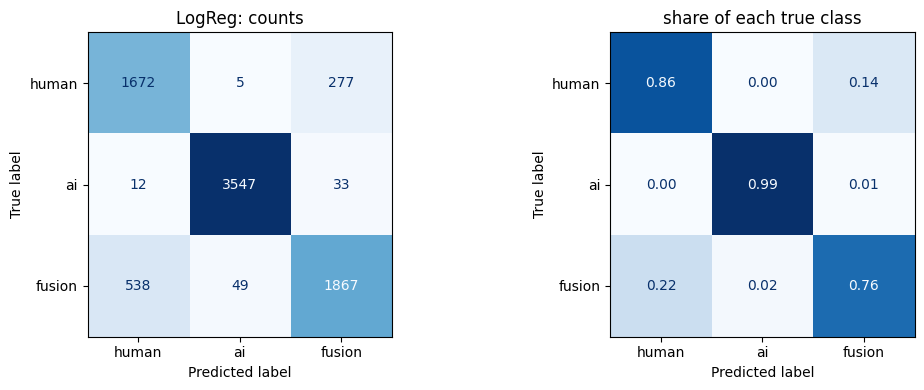

macro-F1 by language: {'de-DE': 0.877, 'en-EN': 0.861}


,n,macroF1
domain,,
arxiv_papers,427.0,0.838
blog_authorship_corpus,1160.0,0.755
bundestag,1535.0,0.879
cnn_news,1290.0,0.864
euro_court_cases,862.0,0.908
gutenberg,199.0,0.758
house_of_commons,948.0,0.867
student_essays,1579.0,0.895


In [5]:
print(classification_report(yva, pva, target_names=LABELS, digits=3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(yva, pva), display_labels=LABELS).plot(cmap="Blues", ax=ax[0], colorbar=False); ax[0].set_title(f"{best_name}: counts")
ConfusionMatrixDisplay(confusion_matrix(yva, pva, normalize="true"), display_labels=LABELS).plot(cmap="Blues", ax=ax[1], colorbar=False, values_format=".2f"); ax[1].set_title("share of each true class"); plt.tight_layout(); plt.show()

d = va.assign(y=yva, p=pva)
print("macro-F1 by language:", d.groupby("lang")[["y", "p"]].apply(lambda g: mf1(g.y, g.p)).round(3).to_dict())
display(d.groupby("domain")[["y", "p"]].apply(lambda g: pd.Series({"n": len(g), "macroF1": mf1(g.y, g.p)})).round(3))

## 5. What did the model learn? (sanity check)
The words with the largest positive weight for each class in the Logistic Regression (word features only). Useful for the EDA / explainability part of the report.

In [6]:
lr = models["LogReg"]; names = np.array(vw.get_feature_names_out())
for i, l in enumerate(LABELS): print(f"{l:7s}->", ", ".join(names[np.argsort(-lr.coef_[i][:n_w])[:25]]))

human  -> dank, vielen dank, of the, vielen, in the, herzlichen dank, herzlichen, that is, urllink, in conclusion, very, danke, this is, to the, have, auch, it is, im, will, should, to be, are, noch, which, go
ai     -> let, text, we, gotta, potential, unsere, just, super, hey, maybe, this, significant, us, 2023, like, honestly, think about, it like, our, these, kinda, lassen sie, felt, legal, feels
fusion -> me know, missing, know if, let me, and, missing part, sondern auch, the, wir müssen, missing section, müssen uns, nicht nur, es ist, we must, furthermore, reconstructed, section, frau präsidentin, wir stehen, despite, hier, he, präsidentin, dass wir, and end


## 6. Save outputs
Probabilities of the LogReg model (for the later ensemble) and a baseline submission file. **Nothing is submitted to Kaggle.**

In [7]:
t0 = time.time(); Xte = hstack([vw.transform(test.text), vc.transform(test.text)]).tocsr(); print(f"test vectorised in {time.time()-t0:.0f}s")
np.savez(f"{OUT_DIR}/tfidf_probs.npz", yva=yva, P_va=lr.predict_proba(Xva), P_te=lr.predict_proba(Xte))
assert set(sub_tmpl.label.unique()) <= set(LABELS)
out = pd.DataFrame({"id": test.id.values, "label": [LABELS[i] for i in base.predict(Xte)]}).set_index("id").loc[sub_tmpl.id].reset_index()
assert list(out.columns) == ["id", "label"] and len(out) == 25000 and out.id.is_unique and out.label.isin(LABELS).all()
out.to_csv(f"{OUT_DIR}/sub_tfidf_baseline.csv", index=False); res_df.to_csv(f"{OUT_DIR}/param_search.csv", index=False); print("saved; test label shares:", out.label.value_counts(normalize=True).round(3).to_dict())

test vectorised in 153s
saved; test label shares: {'ai': 0.516, 'human': 0.28, 'fusion': 0.203}


### TF-IDF Baseline — Conclusions

The TF-IDF baseline achieved a validation macro-F1 of **0.8644** using Logistic Regression (C = 3), outperforming LinearSVC (0.8440). Both models used a combination of word-level (1–2) and character-level (2–5) TF-IDF features.

AI-generated texts were classified with very high accuracy (F1 = 0.986), while human and fusion texts were considerably harder to distinguish (F1 = 0.801 and 0.806, respectively). Fusion had the lowest recall (0.761), making it the main target for further improvements.

Performance was relatively consistent across languages, with macro-F1 scores of 0.877 for German and 0.861 for English.

The most influential lexical features included potential dataset-specific artifacts, such as "missing section" and "reconstructed". This suggests that the model may partially rely on generation-related patterns rather than purely stylistic differences.

The baseline provides a strong reference for subsequent experiments. Future improvements should focus on distinguishing human and fusion texts, evaluating performance across domains, and exploring complementary features or model ensembles.